# 🥗 NutriBot: asistente de nutrición con RAG, herramientas y MCP

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/TU_USUARIO/TU_REPOSITORIO/blob/main/Sesion6/nutribot.ipynb)

**Curso:** Procesamiento de Lenguaje Natural · **Sesión 6:** Herramientas, agentes y MCP
**Autor:** _Tu nombre_

Este notebook es un caso propio basado en los tres notebooks guía de la sesión. En lugar de la calculadora y el clima, construyo un **asistente de nutrición** que:

1. responde preguntas de alimentación saludable **citando** 12 guías (OMS, ICBF, Ministerio de Salud de Colombia), usando **RAG**;
2. calcula el **IMC** y las **calorías diarias** con fórmulas exactas;
3. consulta una **base de 54 alimentos**;
4. expone esas capacidades en **dos servidores MCP propios**, consumidos por un agente con un LLM local (Ollama);
5. se usa desde un **chat en Gradio** que muestra las fuentes de cada respuesta.

### Cómo ejecutarlo
1. En Colab: **Entorno de ejecución → Cambiar tipo de entorno → GPU T4**.
2. En la celda 2.2, pon tu usuario y repositorio de GitHub (de ahí se descargan los servidores MCP y los datos).
3. **Entorno de ejecución → Ejecutar todas.** Tarda entre 10 y 15 minutos y no requiere otra intervención.

### Contenido
1. El problema y la propuesta
2. Preparación del entorno
3. Datos y análisis exploratorio (EDA)
4. Experimento: ¿qué buscador encuentra mejor la guía correcta?
5. Servidores MCP
6. El agente: LLM solo vs agente con herramientas
7. Chatbot con Gradio
8. Conclusiones

## 1. El problema y la propuesta

Mucha gente busca información de nutrición en internet o en chatbots, un tema con mucha desinformación. Un LLM pequeño usado por sí solo tiene tres problemas en este dominio:

| Problema | Ejemplo |
|---|---|
| Inventa cifras de las guías | Decir que la OMS recomienda "máximo 50 g de sal" (lo correcto es menos de 5 g) |
| Se equivoca en la aritmética | Calcular mal un IMC o las calorías diarias |
| No dice de dónde sale la información | El usuario no puede verificar la respuesta |

**Propuesta:** un agente que decide qué herramienta usar, con las herramientas repartidas en dos servidores MCP:

```
Usuario → Gradio → Agente (LangChain) ↔ LLM local (Ollama)
                        │  MCP por HTTP
          ┌─────────────┴──────────────┐
   GuiasNutricion :9082          Nutricion :9083
   · buscar_guias (RAG)          · calcular_imc
     sobre 12 guías              · calcular_calorias
                                 · consultar_alimento (54 alimentos)
```

**Por qué es una buena solución:**
- **RAG** evita que el modelo invente cifras: responde con fragmentos de las guías y cita la fuente de cada uno.
- **Herramientas** evitan los errores aritméticos: el LLM decide *qué* calcular y Python hace el cálculo.
- **MCP** separa responsabilidades, como en el notebook guía 2: cada servidor se prueba y se reutiliza por separado.
- **Ollama local**: las preguntas de salud incluyen datos personales (peso, edad) que así no salen de la máquina.

**Qué agrego respecto a los notebooks guía:** un dominio y datos propios, RAG con citas, EDA, un experimento para elegir el buscador, una comparación de dos modelos contra el LLM sin herramientas, y un chat que siempre muestra las fuentes.

> **Nota ética:** es un proyecto académico y no reemplaza a un profesional de la salud. Las guías son resúmenes propios de documentos públicos y los valores de los alimentos son aproximados.

## 2. Preparación del entorno

### 2.1 Dependencias

In [1]:
import warnings
warnings.filterwarnings('ignore')

try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

In [2]:
!test '{IN_COLAB}' = 'True' && pip install -q "mcp>=1.24.0,<2.0.0" "langchain-mcp-adapters>=0.3.0,<0.4.0" "langchain>=1.0,<2.0" langchain-core langchain-ollama langgraph ollama gradio rank_bm25

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 234.6/234.6 kB 20.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 80.4/80.4 kB 9.0 MB/s eta 0:00:00


### 2.2 Descargar los servidores MCP y los datos desde GitHub
Igual que en el notebook guía, los servidores MCP viven como archivos Python en el repositorio:

```
Sesion6/
├── nutribot.ipynb
├── mcp_servers/
│   ├── guias_server.py       ← servidor MCP 1: búsqueda en guías (RAG)
│   └── nutricion_server.py   ← servidor MCP 2: IMC, calorías y alimentos
└── datos/
    ├── guias/                ← 12 guías de nutrición en Markdown
    └── alimentos.csv         ← 54 alimentos con su composición por 100 g
```

En Colab, al abrir el notebook desde GitHub, esos archivos no se descargan solos; esta celda los baja. Si ejecutas el notebook dentro del repositorio clonado, usa los archivos locales.

In [3]:
import urllib.request
from pathlib import Path

GITHUB_USUARIO = 'sam2800ml'
GITHUB_REPO = 'nlp-icesi'
URL_BASE = f'https://raw.githubusercontent.com/{GITHUB_USUARIO}/{GITHUB_REPO}/main/Sesion6'

NOMBRES_GUIAS = ['01_plato_saludable_colombia', '02_azucares_y_bebidas', '03_sodio_y_sal', '04_grasas',
                 '05_proteinas', '06_frutas_verduras_y_fibra', '07_hidratacion', '08_actividad_fisica',
                 '09_imc_y_peso_saludable', '10_etiquetado_frontal_colombia', '11_ultraprocesados_nova',
                 '12_planificacion_de_comidas']
ARCHIVOS = (['mcp_servers/guias_server.py', 'mcp_servers/nutricion_server.py', 'datos/alimentos.csv']
            + [f'datos/guias/{nombre}.md' for nombre in NOMBRES_GUIAS])


if all((Path.cwd() / a).exists() for a in ARCHIVOS):
    PROYECTO = Path.cwd()
elif all((Path.cwd() / 'Sesion6' / a).exists() for a in ARCHIVOS):
    PROYECTO = Path.cwd() / 'Sesion6'
else:
    if GITHUB_USUARIO == 'TU_USUARIO':
        raise RuntimeError('Configura GITHUB_USUARIO y GITHUB_REPO para descargar los archivos del proyecto.')
    PROYECTO = Path.cwd() / 'Sesion6'
    for archivo in ARCHIVOS:
        (PROYECTO / archivo).parent.mkdir(parents=True, exist_ok=True)
        urllib.request.urlretrieve(f'{URL_BASE}/{archivo}', PROYECTO / archivo)
    print(f'Descargados {len(ARCHIVOS)} archivos desde {URL_BASE}')

print('Carpeta del proyecto:', PROYECTO)

Descargados 15 archivos desde https://raw.githubusercontent.com/sam2800ml/nlp-icesi/main/Sesion6
Carpeta del proyecto: /content/Sesion6


### 2.3 Ollama
En los notebooks guía había que abrir una terminal para ejecutar `ollama serve`. Aquí lo lanzo en segundo plano desde Python, para que el notebook corra completo con "Ejecutar todas".

Uso dos modelos de chat de tamaño parecido para compararlos (`llama3.2:3b`, el de la guía, y `qwen2.5:3b`) y dos modelos de embeddings para el experimento del buscador (`nomic-embed-text` y el multilingüe `bge-m3`).

In [4]:
import shutil
import subprocess
import time
import ollama

def ollama_activo():
    try:
        ollama.list()
        return True
    except Exception:
        return False

if not ollama_activo():
    if shutil.which('ollama') is None:
        print('Instalando Ollama...')
        subprocess.run('apt-get -qq install -y zstd > /dev/null; curl -fsSL https://ollama.com/install.sh | sh > /dev/null',
                       shell=True, check=True)
    subprocess.Popen(['ollama', 'serve'], stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)
    while not ollama_activo():
        time.sleep(1)
print('Ollama activo')

MODELOS_CHAT = ['llama3.2:3b', 'qwen2.5:3b']
MODELOS_EMBEDDINGS = ['nomic-embed-text', 'bge-m3']
for modelo in MODELOS_CHAT + MODELOS_EMBEDDINGS:
    ollama.pull(modelo)
    print('Modelo listo:', modelo)

Instalando Ollama...
Ollama activo
Modelo listo: llama3.2:3b
Modelo listo: qwen2.5:3b
Modelo listo: nomic-embed-text
Modelo listo: bge-m3


In [5]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

sns.set_theme(style='whitegrid')
plt.rcParams['figure.dpi'] = 110

## 3. Datos y análisis exploratorio (EDA)

### 3.1 Las guías
Escribí 12 guías en Markdown, cada una con un título (`#`) y varias secciones (`##`). Para el RAG, cada **sección** será un fragmento (*chunk*): es una unidad de significado completa y permite citar exactamente de dónde sale cada dato. Esta es la misma función que usa el servidor MCP de guías.

In [6]:
def cargar_fragmentos(carpeta):
    """Divide cada guía en fragmentos, uno por sección (##), guardando de dónde viene cada uno."""
    fragmentos = []
    for archivo in sorted(carpeta.glob('*.md')):
        texto = archivo.read_text(encoding='utf-8')
        titulo = texto.splitlines()[0].lstrip('# ')
        for bloque in texto.split('\n## ')[1:]:
            seccion, _, contenido = bloque.partition('\n')
            fragmentos.append({
                'guia': archivo.stem,
                'fuente': f'{archivo.name} › {seccion.strip()}',
                'texto': f"{titulo} > {seccion.strip()}. {' '.join(contenido.split())}",
            })
    return fragmentos

fragmentos = cargar_fragmentos(PROYECTO / 'datos' / 'guias')
df_frag = pd.DataFrame(fragmentos)
df_frag['palabras'] = df_frag.texto.str.split().str.len()
print(f'{df_frag.guia.nunique()} guías, {len(df_frag)} fragmentos, {df_frag.palabras.sum()} palabras')
print('\nEjemplo de fragmento:\n', fragmentos[8]['fuente'], '\n', fragmentos[8]['texto'][:300], '...')

12 guías, 63 fragmentos, 4301 palabras

Ejemplo de fragmento:
 02_azucares_y_bebidas.md › Impuestos saludables en Colombia 
 Azúcares libres y bebidas azucaradas > Impuestos saludables en Colombia. Colombia adoptó, mediante la Ley 2277 de 2022, un impuesto a las bebidas ultraprocesadas azucaradas y a ciertos productos comestibles ultraprocesados con alto contenido de azúcar, sodio o grasas saturadas. El objetivo de esta m ...


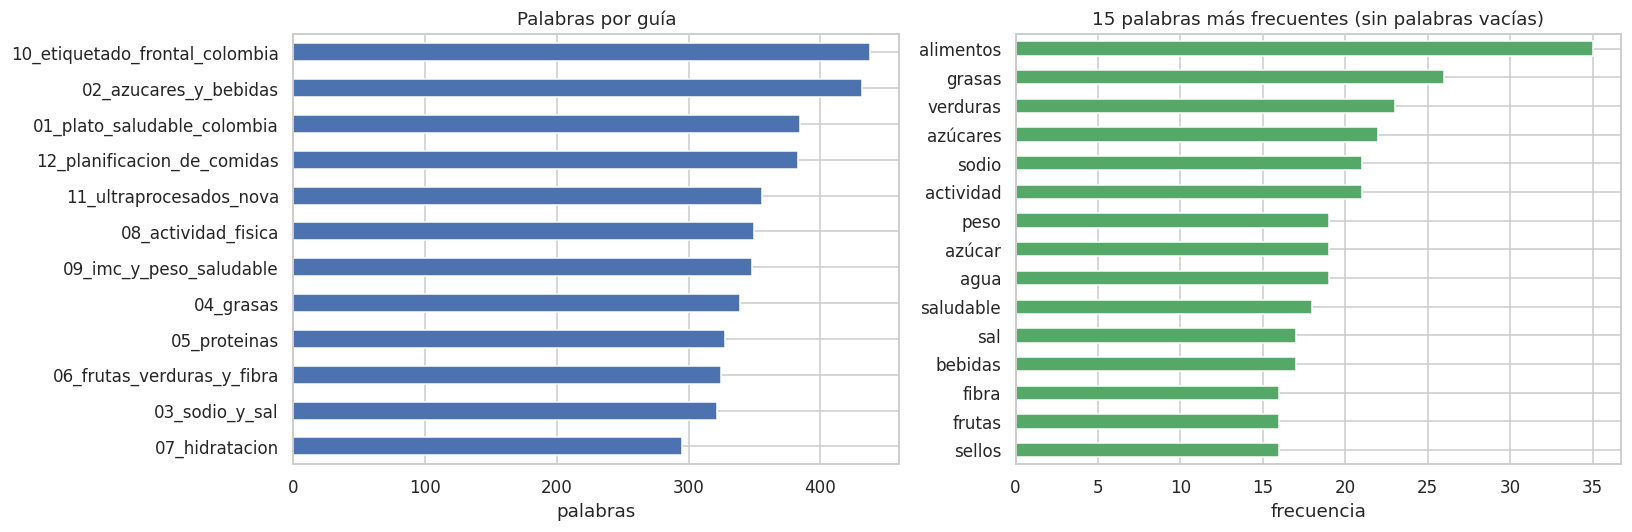

Palabras por fragmento: media 68 | mín 32 | máx 143


In [7]:
from collections import Counter

PALABRAS_VACIAS = set('de la el en y a los las del que se un una por con para es al lo como su sus o más menos no '
                      'son cada pero sin entre puede ser también este esta muy hay sobre ya le'.split())
conteo = Counter(p for t in df_frag.texto for p in re.findall(r'[a-záéíóúñ]+', t.lower())
                 if p not in PALABRAS_VACIAS and len(p) > 2)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
df_frag.groupby('guia').palabras.sum().sort_values().plot.barh(ax=axes[0], color='#4C72B0')
axes[0].set(title='Palabras por guía', xlabel='palabras', ylabel='')
top = pd.Series(dict(conteo.most_common(15))).sort_values()
top.plot.barh(ax=axes[1], color='#55A868')
axes[1].set(title='15 palabras más frecuentes (sin palabras vacías)', xlabel='frecuencia')
plt.tight_layout()
plt.show()

print('Palabras por fragmento: media', round(df_frag.palabras.mean()), '| mín', df_frag.palabras.min(),
      '| máx', df_frag.palabras.max())

**Observaciones del corpus.** Son 12 guías con 63 secciones. Están equilibradas en tamaño (entre unas 300 y 440 palabras contando los encabezados), así que ninguna domina la búsqueda por ser más larga. Cada fragmento tiene entre 30 y 140 palabras, un tamaño cómodo para pasarle 3 al LLM sin llenar su contexto. Las palabras más frecuentes (alimentos, azúcar, grasas, verduras, agua, sodio, peso) coinciden con los grandes temas del corpus. Varias guías comparten vocabulario (por ejemplo, el azúcar aparece en las guías de azúcares, etiquetado y ultraprocesados), lo que puede confundir a un buscador por palabras clave; el experimento de la sección 4 lo mide.

### 3.2 La base de alimentos

In [8]:
alimentos = pd.read_csv(PROYECTO / 'datos' / 'alimentos.csv')
display(alimentos.head())
display(alimentos.describe().round(1))

,alimento,categoria,kcal,proteina_g,carbohidratos_g,grasa_g,fibra_g,azucar_g,sodio_mg
0,arroz blanco cocido,cereales y tubérculos,130,2.7,28.2,0.3,0.4,0.1,1
1,arroz integral cocido,cereales y tubérculos,123,2.7,25.6,1.0,1.6,0.2,4
2,pasta cocida,cereales y tubérculos,158,5.8,30.9,0.9,1.8,0.6,1
3,pan blanco,cereales y tubérculos,265,9.0,49.0,3.2,2.7,5.0,490
4,pan integral,cereales y tubérculos,247,13.0,41.0,3.4,7.0,6.0,450


,kcal,proteina_g,carbohidratos_g,grasa_g,fibra_g,azucar_g,sodio_mg
count,54.0,54.0,54.0,54.0,54.0,54.0,54.0
mean,186.8,7.8,17.8,10.0,2.4,7.0,107.2
std,196.6,9.1,21.7,21.2,3.0,17.4,214.6
min,15.0,0.0,0.0,0.0,0.0,0.0,0.0
25%,50.5,0.9,3.7,0.2,0.0,0.4,2.0
50%,122.5,3.0,10.7,0.8,1.6,2.6,7.5
75%,236.8,12.0,22.8,5.8,2.7,5.1,60.8
max,884.0,31.0,100.0,100.0,12.5,100.0,1010.0


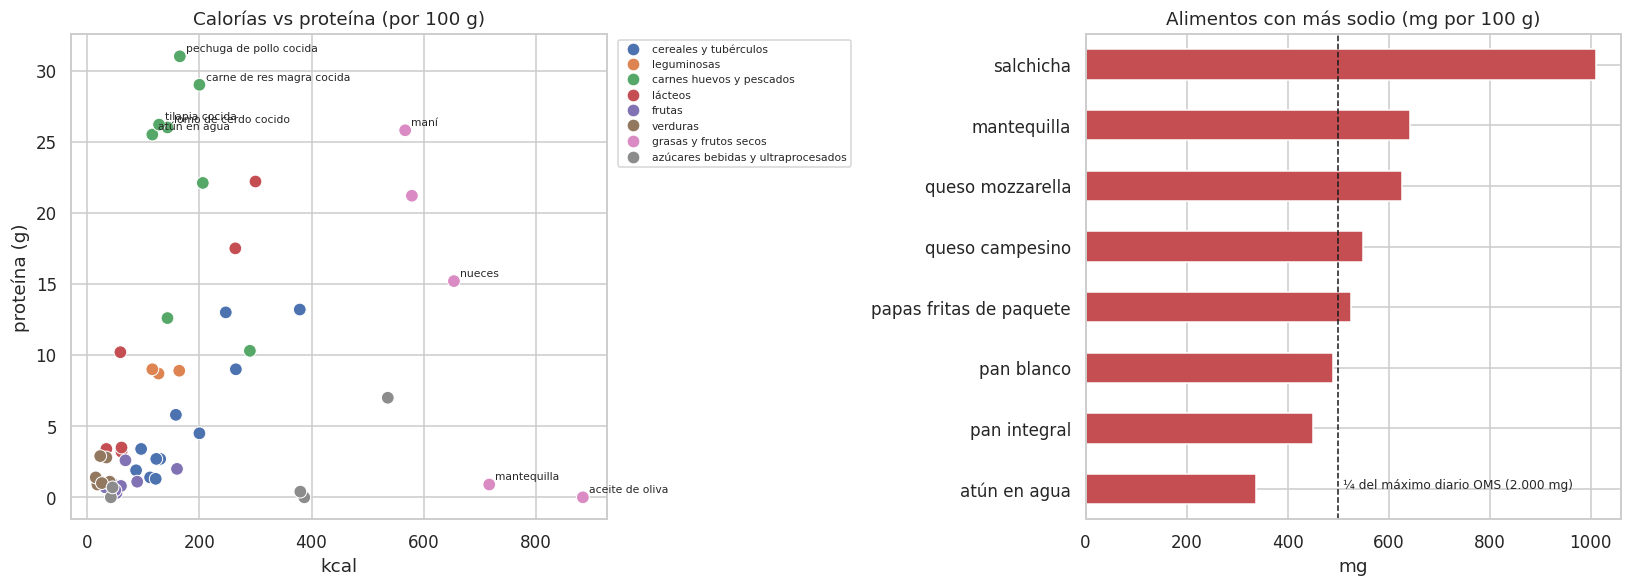

,kcal,proteina_g,fibra_g,sodio_mg
categoria,,,,
verduras,26.0,1.1,1.7,28.0
frutas,52.0,0.8,2.4,1.0
lácteos,61.0,6.8,0.0,44.5
leguminosas,127.0,8.9,7.6,2.0
cereales y tubérculos,130.0,3.4,2.3,4.0
carnes huevos y pescados,154.0,25.8,0.0,67.5
azúcares bebidas y ultraprocesados,380.0,0.4,0.0,4.0
grasas y frutos secos,654.0,15.2,6.7,2.0


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
sns.scatterplot(data=alimentos, x='kcal', y='proteina_g', hue='categoria', s=70, ax=axes[0])
for _, fila in alimentos[(alimentos.proteina_g > 24) | (alimentos.kcal > 600)].iterrows():
    axes[0].annotate(fila.alimento, (fila.kcal, fila.proteina_g), fontsize=7, xytext=(4, 3), textcoords='offset points')
axes[0].set(title='Calorías vs proteína (por 100 g)', xlabel='kcal', ylabel='proteína (g)')
axes[0].legend(fontsize=7, bbox_to_anchor=(1.01, 1), loc='upper left')

alimentos.nlargest(8, 'sodio_mg').set_index('alimento').sodio_mg.sort_values().plot.barh(ax=axes[1], color='#C44E52')
axes[1].axvline(500, ls='--', c='k', lw=1)
axes[1].text(510, 0, '¼ del máximo diario OMS (2.000 mg)', fontsize=8)
axes[1].set(title='Alimentos con más sodio (mg por 100 g)', xlabel='mg', ylabel='')
plt.tight_layout()
plt.show()

display(alimentos.groupby('categoria')[['kcal', 'proteina_g', 'fibra_g', 'sodio_mg']].median().round(1)
        .sort_values('kcal'))

**Observaciones de los alimentos.**
- Las calorías varían muchísimo: la mediana es de 26 kcal por 100 g en verduras y de 654 en grasas y frutos secos (el aceite de oliva llega a 884). Por eso el tamaño de la porción importa mucho más en los alimentos grasos.
- Las carnes y pescados magros (pechuga de pollo, tilapia, atún) dan mucha proteína con pocas calorías, mientras que los frutos secos dan proteína pero con muchas calorías.
- El sodio se concentra en los procesados: 100 g de salchicha tienen 1.010 mg, la mitad del máximo diario de la OMS. Le siguen la mantequilla con sal, los quesos, las papas fritas de paquete y el pan, lo que coincide con lo que dice la guía de sodio sobre las "fuentes ocultas".
- 19 de los 54 alimentos no tienen fibra (carnes, lácteos, grasas y azúcares).

## 4. Experimento: ¿qué buscador encuentra mejor la guía correcta?

El RAG solo funciona si el buscador trae el fragmento correcto. Comparo tres buscadores:
- **BM25:** búsqueda por palabras clave (léxica). No usa ningún modelo.
- **Embeddings con `nomic-embed-text`:** búsqueda por significado (semántica), con un modelo entrenado principalmente en inglés.
- **Embeddings con `bge-m3`:** búsqueda semántica con un modelo multilingüe.

Para evaluarlos escribí 12 preguntas como las haría un usuario, cada una con la guía que debería encontrarse. Varias usan palabras distintas a las del texto (por ejemplo "octágono negro" en lugar de "sello de advertencia"). Mido:
- **Acierto@1:** el primer fragmento es de la guía correcta.
- **Acierto@3:** la guía correcta aparece entre los 3 primeros fragmentos, que son los que recibe el LLM.

In [10]:
from rank_bm25 import BM25Okapi

PREGUNTAS_PRUEBA = [
    ('¿Cuántas cucharaditas de azúcar al día es lo ideal según la OMS?', '02_azucares_y_bebidas'),
    ('¿Los jugos de fruta hechos en casa cuentan como azúcar libre?', '02_azucares_y_bebidas'),
    ('¿Qué cantidad máxima de sal debería consumir un adulto?', '03_sodio_y_sal'),
    ('¿Qué tipo de grasas conviene preferir para cuidar el corazón?', '04_grasas'),
    ('¿Cuánta proteína necesita una persona que entrena pesas?', '05_proteinas'),
    ('¿Por qué es bueno combinar fríjoles con arroz?', '05_proteinas'),
    ('¿Cuánta agua debe tomar una mujer adulta al día?', '07_hidratacion'),
    ('¿Cuántos minutos de ejercicio a la semana se recomiendan para adultos?', '08_actividad_fisica'),
    ('¿Qué medida de cintura indica riesgo para la salud?', '09_imc_y_peso_saludable'),
    ('¿Qué significa que un producto tenga un octágono negro?', '10_etiquetado_frontal_colombia'),
    ('¿Cómo reconozco si un producto es ultraprocesado?', '11_ultraprocesados_nova'),
    ('¿Cómo armo un almuerzo balanceado usando la mano para medir porciones?', '12_planificacion_de_comidas'),
]
textos = [f['texto'] for f in fragmentos]

def tokenizar(texto):
    return re.findall(r'\w+', texto.lower())

def embeber(textos, modelo, es_pregunta=False):
    if modelo == 'nomic-embed-text':  # este modelo funciona mejor con prefijos de tarea
        textos = [('search_query: ' if es_pregunta else 'search_document: ') + t for t in textos]
    vectores = np.array(ollama.embed(model=modelo, input=textos)['embeddings'])
    return vectores / np.linalg.norm(vectores, axis=1, keepdims=True)

def crear_buscador(nombre):
    """Devuelve una función que recibe una pregunta y retorna los índices de los fragmentos ordenados."""
    if nombre == 'bm25':
        bm25 = BM25Okapi([tokenizar(t) for t in textos])
        return lambda pregunta: np.argsort(bm25.get_scores(tokenizar(pregunta)))[::-1]
    vectores = embeber(textos, nombre)
    return lambda pregunta: np.argsort(vectores @ embeber([pregunta], nombre, es_pregunta=True)[0])[::-1]

filas = []
for nombre in ['bm25'] + MODELOS_EMBEDDINGS:
    buscar = crear_buscador(nombre)
    for pregunta, guia_correcta in PREGUNTAS_PRUEBA:
        top3 = [fragmentos[i]['guia'] for i in buscar(pregunta)[:3]]
        filas.append({'buscador': nombre, 'pregunta': pregunta, 'guia_correcta': guia_correcta, 'top3': top3,
                      'acierto@1': top3[0] == guia_correcta, 'acierto@3': guia_correcta in top3})

resultados_busqueda = pd.DataFrame(filas)
resumen_busqueda = resultados_busqueda.groupby('buscador')[['acierto@1', 'acierto@3']].mean()
resumen_busqueda = resumen_busqueda.sort_values(['acierto@1', 'acierto@3'], ascending=False)
display(resumen_busqueda.round(2))

,acierto@1,acierto@3
buscador,,
bge-m3,1.00,1.00
nomic-embed-text,0.92,0.92
bm25,0.83,1.00


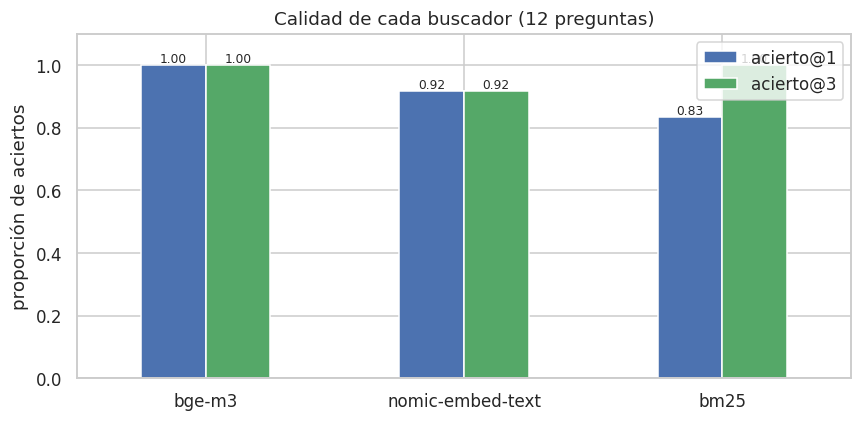

Mejor buscador: bge-m3. Es el que usará el servidor MCP de guías.

Preguntas en las que el mejor buscador no acertó en el primer lugar:


'Ninguna'

In [11]:
ax = resumen_busqueda.plot.bar(figsize=(8, 4), rot=0, color=['#4C72B0', '#55A868'])
ax.set(title='Calidad de cada buscador (12 preguntas)', ylabel='proporción de aciertos', ylim=(0, 1.1), xlabel='')
for barras in ax.containers:
    ax.bar_label(barras, fmt='%.2f', fontsize=8)
plt.tight_layout()
plt.show()

BUSCADOR = resumen_busqueda.index[0]
print(f'Mejor buscador: {BUSCADOR}. Es el que usará el servidor MCP de guías.\n')
print('Preguntas en las que el mejor buscador no acertó en el primer lugar:')
fallos = resultados_busqueda[(resultados_busqueda.buscador == BUSCADOR) & ~resultados_busqueda['acierto@1']]
display(fallos[['pregunta', 'guia_correcta', 'top3']] if len(fallos) else 'Ninguna')

**Análisis.**
- **BM25** funciona bien cuando la pregunta comparte palabras con la guía ("sal", "proteína"), pero falla con sinónimos o paráfrasis: "octágono negro" no aparece literalmente en el texto, que habla de "sellos octagonales".
- **Los embeddings** comparan el significado, así que manejan mejor las paráfrasis; a cambio, pueden confundir guías de temas cercanos (azúcares, etiquetado y ultraprocesados).
- **El modelo multilingüe** (`bge-m3`) tiene más del triple de parámetros que `nomic-embed-text`; la tabla muestra si ese costo se traduce en mejores resultados con textos en español.
- **Acierto@3** suele ser más alto que **Acierto@1**: aunque el primer fragmento no sea el ideal, el correcto casi siempre llega entre los 3 que recibe el LLM. Por eso el servidor devuelve 3 fragmentos y no solo 1.

El notebook elige automáticamente el buscador con mejor resultado y se lo pasa al servidor MCP.

## 5. Servidores MCP

### 5.1 El código de los servidores
Ambos siguen la misma estructura del notebook guía: crear un `FastMCP`, decorar funciones con `@mcp.tool()` y ejecutar con transporte HTTP. **El docstring de cada herramienta es clave**, porque es lo que lee el LLM para decidir cuándo usarla.

In [12]:
print((PROYECTO / 'mcp_servers' / 'guias_server.py').read_text(encoding='utf-8'))

"""Servidor MCP 1: búsqueda en las guías de nutrición (RAG)."""
import os
import re
from pathlib import Path

import numpy as np
import ollama
from mcp.server.fastmcp import FastMCP
from rank_bm25 import BM25Okapi

CARPETA_GUIAS = Path(__file__).resolve().parent.parent / "datos" / "guias"
# Buscador a usar: 'bm25', 'nomic-embed-text' o 'bge-m3' (el notebook elige el mejor y lo pasa aquí)
BUSCADOR = os.environ.get("BUSCADOR", "nomic-embed-text")

mcp = FastMCP("GuiasNutricion", host="localhost", port=9082)


def cargar_fragmentos():
    """Divide cada guía en fragmentos, uno por sección (##), guardando de dónde viene cada uno."""
    fragmentos = []
    for archivo in sorted(CARPETA_GUIAS.glob("*.md")):
        texto = archivo.read_text(encoding="utf-8")
        titulo = texto.splitlines()[0].lstrip("# ")
        for bloque in texto.split("\n## ")[1:]:
            seccion, _, contenido = bloque.partition("\n")
            fragmentos.append({
                "fuente": f"{archivo.name} › 

In [13]:
print((PROYECTO / 'mcp_servers' / 'nutricion_server.py').read_text(encoding='utf-8'))

"""Servidor MCP 2: cálculos de salud y base de datos de alimentos."""
import csv
import unicodedata
from pathlib import Path

from mcp.server.fastmcp import FastMCP

RUTA_ALIMENTOS = Path(__file__).resolve().parent.parent / "datos" / "alimentos.csv"
mcp = FastMCP("Nutricion", host="localhost", port=9083)


def normalizar(texto):
    """Minúsculas y sin tildes, para que 'fríjol' y 'frijol' coincidan."""
    texto = unicodedata.normalize("NFKD", texto.lower().strip())
    return "".join(c for c in texto if not unicodedata.combining(c))


with open(RUTA_ALIMENTOS, encoding="utf-8") as f:
    ALIMENTOS = list(csv.DictReader(f))


@mcp.tool()
def calcular_imc(peso_kg: float, estatura_m: float) -> str:
    """Calcula el índice de masa corporal (IMC) y su clasificación según la OMS.

    peso_kg: peso en kilogramos. estatura_m: estatura en metros (por ejemplo 1.70).
    """
    if estatura_m > 3:  # los modelos pequeños a veces envían la estatura en centímetros
        estatura_m = estatura_m

Dos detalles del servidor de nutrición pensados para los modelos pequeños: si el modelo envía la estatura en centímetros en lugar de metros, `calcular_imc` la corrige; y `consultar_alimento` ignora tildes y plurales, para que "fríjoles" encuentre "fríjol rojo cocido".

### 5.2 Iniciar los servidores
Como en el notebook guía, cada servidor corre como un proceso aparte, en los puertos 9082 y 9083. Al servidor de guías le paso el buscador elegido en la sección 4 mediante la variable de entorno `BUSCADOR`.

In [14]:
import os
import socket
import sys

def puerto_abierto(puerto):
    with socket.socket() as s:
        return s.connect_ex(('localhost', puerto)) == 0

servidores = {}
for nombre, puerto in [('guias_server', 9082), ('nutricion_server', 9083)]:
    if puerto_abierto(puerto):
        print(f'{nombre} ya estaba corriendo en el puerto {puerto}')
        continue
    servidores[nombre] = subprocess.Popen(
        [sys.executable, str(PROYECTO / 'mcp_servers' / f'{nombre}.py')],
        env={**os.environ, 'BUSCADOR': BUSCADOR},
        stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL,
    )
    while not puerto_abierto(puerto):  # el servidor de guías tarda unos segundos calculando embeddings
        if servidores[nombre].poll() is not None:
            raise RuntimeError(f'El servidor {nombre} se detuvo. Ejecútalo en una terminal para ver el error.')
        time.sleep(0.5)
    print(f'{nombre} corriendo en http://localhost:{puerto}/mcp')

guias_server corriendo en http://localhost:9082/mcp
nutricion_server corriendo en http://localhost:9083/mcp


### 5.3 Probar el protocolo directamente
Antes de usar un agente, me conecto con un cliente MCP explícito (`ClientSession`, como en el notebook guía 2) para listar las herramientas y llamarlas sin LLM. Así compruebo que los servidores responden bien.

In [15]:
from mcp import ClientSession
from mcp.client.streamable_http import streamable_http_client

async def llamar_herramienta(puerto, herramienta, argumentos):
    async with streamable_http_client(f'http://localhost:{puerto}/mcp') as (read, write, _):
        async with ClientSession(read, write) as sesion:
            await sesion.initialize()
            nombres = [t.name for t in (await sesion.list_tools()).tools]
            resultado = await sesion.call_tool(herramienta, argumentos)
            return nombres, resultado.content[0].text

pruebas = [
    (9082, 'buscar_guias', {'pregunta': '¿Cuánta sal puedo comer al día?'}),
    (9083, 'calcular_imc', {'peso_kg': 72, 'estatura_m': 1.70}),
    (9083, 'calcular_calorias', {'peso_kg': 60, 'estatura_cm': 165, 'edad': 30, 'sexo': 'mujer'}),
    (9083, 'consultar_alimento', {'nombre': 'pechuga de pollo', 'gramos': 150}),
]
for puerto, herramienta, argumentos in pruebas:
    nombres, salida = await llamar_herramienta(puerto, herramienta, argumentos)
    print(f'Puerto {puerto} · herramientas: {nombres}\n▶ {herramienta}({argumentos})\n{salida[:500]}\n')

Puerto 9082 · herramientas: ['buscar_guias']
▶ buscar_guias({'pregunta': '¿Cuánta sal puedo comer al día?'})
[Fuente: 03_sodio_y_sal.md › Recomendación diaria]
Sodio y sal > Recomendación diaria. La OMS recomienda que los adultos consuman menos de 2 gramos de sodio al día, lo que equivale a menos de 5 gramos de sal, aproximadamente una cucharadita rasa. Para los niños la cantidad máxima debe ajustarse a la baja según su necesidad de energía. La mayoría de las personas en el mundo consumen casi el doble de lo recomendado.

[Fuente: 03_sodio_y_sal.md › Sodio y sal no son lo mismo]
Sodio y sal > Sodio y s

Puerto 9083 · herramientas: ['calcular_imc', 'calcular_calorias', 'consultar_alimento']
▶ calcular_imc({'peso_kg': 72, 'estatura_m': 1.7})
IMC = 24.9 kg/m². Clasificación OMS: peso normal.

Puerto 9083 · herramientas: ['calcular_imc', 'calcular_calorias', 'consultar_alimento']
▶ calcular_calorias({'peso_kg': 60, 'estatura_cm': 165, 'edad': 30, 'sexo': 'mujer'})
Metabolismo basal: 1320 k

## 6. El agente: LLM solo vs agente con herramientas

### 6.1 Crear el agente
`MultiServerMCPClient` se conecta a los dos servidores y convierte sus herramientas MCP en herramientas de LangChain. Le doy al agente un *system prompt* con reglas claras sobre cuándo usar cada herramienta y cómo citar. Ajusto dos parámetros del modelo: `temperature=0`, para que las respuestas sean reproducibles, y `num_ctx=8192`, porque el contexto por defecto de Ollama se queda corto con los fragmentos recuperados.

In [16]:
from langchain.agents import create_agent
from langchain_mcp_adapters.client import MultiServerMCPClient
from langchain_ollama import ChatOllama

cliente_mcp = MultiServerMCPClient({
    'guias': {'transport': 'http', 'url': 'http://localhost:9082/mcp'},
    'nutricion': {'transport': 'http', 'url': 'http://localhost:9083/mcp'},
})
herramientas = await cliente_mcp.get_tools()
print('Herramientas disponibles:', [h.name for h in herramientas])

PROMPT = """Eres NutriBot, un asistente de nutrición. Responde en español, de forma breve.
Reglas:
1. Para preguntas sobre recomendaciones de alimentación (azúcar, sal, grasas, proteína, agua, ejercicio,
   sellos, ultraprocesados, comidas balanceadas) usa buscar_guias, responde solo con lo que encuentres
   y cita las fuentes tal como aparecen, por ejemplo [Fuente: 03_sodio_y_sal.md › Recomendación diaria].
2. Para el IMC usa calcular_imc y para las calorías diarias usa calcular_calorias. Nunca calcules de memoria.
3. Para los nutrientes de un alimento usa consultar_alimento.
4. No das diagnósticos médicos: ante enfermedades o síntomas recomienda consultar a un profesional."""

def crear_llm(modelo):
    return ChatOllama(model=modelo, temperature=0, num_ctx=8192)

def crear_agente(modelo):
    return create_agent(model=crear_llm(modelo), tools=herramientas, system_prompt=PROMPT)

Herramientas disponibles: ['buscar_guias', 'calcular_imc', 'calcular_calorias', 'consultar_alimento']


In [17]:
def texto_de(contenido):
    """El contenido de un mensaje puede llegar como texto o como lista de bloques; esto lo convierte en texto."""
    if isinstance(contenido, list):
        return '\n'.join(b.get('text', '') if isinstance(b, dict) else str(b) for b in contenido)
    return str(contenido)

async def preguntar(agente, pregunta, historial=()):
    """Devuelve la respuesta del agente, las herramientas que usó y lo que devolvieron."""
    mensajes = list(historial) + [('user', pregunta)]
    resultado = await agente.ainvoke({'messages': mensajes}, config={'recursion_limit': 10})
    nuevos = resultado['messages'][len(mensajes):]
    usadas = [llamada['name'] for m in nuevos for llamada in getattr(m, 'tool_calls', [])]
    salidas = [texto_de(m.content) for m in nuevos if m.type == 'tool']
    return texto_de(nuevos[-1].content), usadas, salidas

agente = crear_agente(MODELOS_CHAT[-1])
respuesta, usadas, salidas = await preguntar(agente, '¿Cuántos gramos de azúcar al día recomienda la OMS?')
print('Herramientas usadas:', usadas)
print('\nLo que devolvió la herramienta:\n', salidas[0][:400] if salidas else '—')
print('\nRespuesta final:\n', respuesta)

Herramientas usadas: ['buscar_guias']

Lo que devolvió la herramienta:
 [Fuente: 02_azucares_y_bebidas.md › Recomendación de la OMS]
Azúcares libres y bebidas azucaradas > Recomendación de la OMS. La OMS recomienda reducir el consumo de azúcares libres a menos del 10 % de la ingesta calórica total, tanto en adultos como en niños. Además, sugiere que reducirlo por debajo del 5 % trae beneficios adicionales para la salud. Para un adulto con una dieta de unas 2000 kiloca

Respuesta final:
 La Organización Mundial de la Salud (OMS) recomienda que los adultos consuman menos de 5 gramos de sal al día, lo que equivale a menos de 2 gramos de sodio. Para el azúcar, la OMS recomienda que el consumo de azúcares libres no supere el 5% de la ingesta calórica total, lo que equivale a aproximadamente 25 gramos de azúcar al día. Para un adulto con una dieta de unas 2000 kilocalorías, esto se traduce en 25 gramos de azúcar. Para un consumo más moderado, el 10% de la ingesta calórica total de azúcares l

### 6.2 Evaluación: ¿mejora el agente frente al LLM solo?
Comparo, con 8 preguntas que tienen respuesta verificable, el **LLM sin herramientas** frente al **agente con herramientas MCP**, para los dos modelos. Una respuesta cuenta como correcta si contiene el valor esperado; los valores salen de las pruebas directas de la sección 5.3 y de las guías. En las preguntas de guías también reviso si la respuesta **cita la fuente**.

In [18]:
PREGUNTAS_AGENTE = [
    # (tipo, pregunta, herramienta esperada, patrón que debe aparecer en una respuesta correcta)
    ('cálculo', '¿Cuál es mi IMC si peso 72 kg y mido 1,70 m?', 'calcular_imc', r'24[.,]9'),
    ('cálculo', 'Peso 95 kilos y mido 1.80 metros, ¿cuál es mi IMC?', 'calcular_imc', r'29[.,]3'),
    ('cálculo', 'Soy mujer, tengo 30 años, peso 60 kg, mido 165 cm y hago actividad moderada. '
                '¿Cuántas calorías necesito al día?', 'calcular_calorias', r'2[.,]?046'),
    ('alimento', '¿Cuánta proteína tienen 150 g de pechuga de pollo?', 'consultar_alimento', r'46[.,]5'),
    ('alimento', '¿Cuántas calorías tienen 200 g de banano?', 'consultar_alimento', r'\b178\b'),
    ('guía', '¿Cuánta azúcar al día recomienda la OMS?', 'buscar_guias', r'\b25\b|\b50\b'),
    ('guía', '¿Cuántos minutos de actividad física a la semana recomienda la OMS para adultos?',
             'buscar_guias', r'\b150\b'),
    ('guía', '¿Cuánta sal máxima debería consumir al día un adulto?', 'buscar_guias', r'\b5\s*(g\b|gramos)'),
]

filas = []
for modelo in MODELOS_CHAT:
    llm, agente = crear_llm(modelo), crear_agente(modelo)
    for tipo, pregunta, esperada, patron in PREGUNTAS_AGENTE:
        sin_tools = texto_de(llm.invoke(pregunta + ' Responde en una o dos frases.').content)
        try:
            con_tools, usadas, _ = await preguntar(agente, pregunta)
        except Exception as error:  # p. ej. el modelo entra en un ciclo de llamadas
            con_tools, usadas = f'Error: {error}', []
        filas.append({
            'modelo': modelo, 'tipo': tipo, 'pregunta': pregunta,
            'correcta sin herramientas': bool(re.search(patron, sin_tools, re.I)),
            'correcta con agente': bool(re.search(patron, con_tools, re.I)),
            'herramienta correcta': esperada in usadas,
            'cita la fuente': ('Fuente' in con_tools or '.md' in con_tools) if tipo == 'guía' else None,
            'respuesta sin herramientas': sin_tools, 'respuesta con agente': con_tools,
        })
    print('Evaluado:', modelo)

evaluacion = pd.DataFrame(filas)
metricas = ['correcta sin herramientas', 'correcta con agente', 'herramienta correcta', 'cita la fuente']
resumen_agente = evaluacion.groupby('modelo')[metricas].agg(lambda s: s.dropna().astype(float).mean())
display(resumen_agente.round(2))

Evaluado: llama3.2:3b
Evaluado: qwen2.5:3b


,correcta sin herramientas,correcta con agente,herramienta correcta,cita la fuente
modelo,,,,
llama3.2:3b,0.38,0.88,1.0,0.0
qwen2.5:3b,0.12,1.00,1.0,0.0


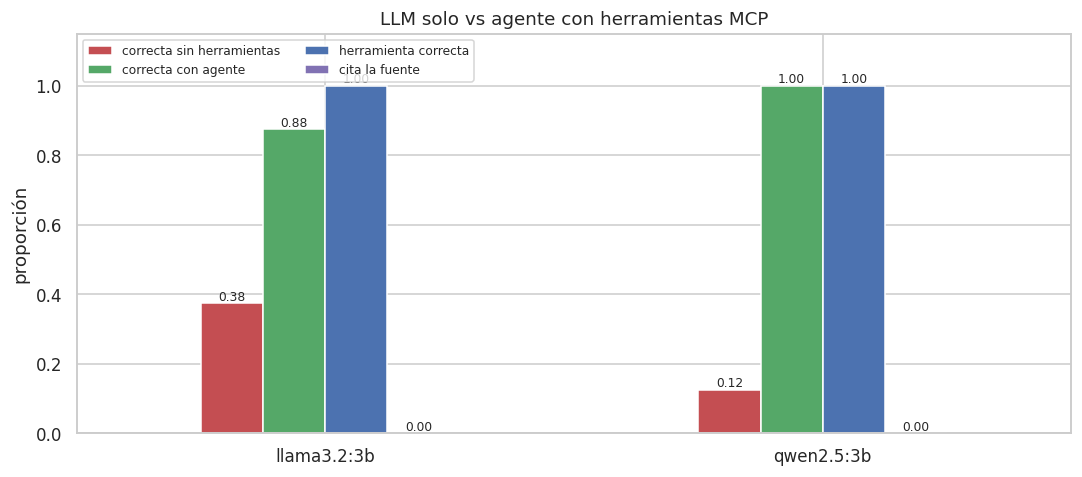

,pregunta,respuesta sin herramientas,respuesta con agente
0,"¿Cuál es mi IMC si peso 72 kg y mido 1,70 m?","Para calcular tu IMC (Índice de Masa Corporal), necesito saber tu edad. Una vez que tenga esa información, puedo cal...","Según la Organización Mundial de la Salud (OMS), un IMC de 24.9 kg/m² se clasifica como peso normal."
1,"Peso 95 kilos y mido 1.80 metros, ¿cuál es mi IMC?","Para calcular tu IMC (Índice de Masa Corporal), necesito saber tu edad. Una vez que tenga esa información, puedo cal...","Según la Organización Mundial de la Salud (OMS), un IMC de 29.3 indica que estás en la categoría de sobrepeso."
2,"Soy mujer, tengo 30 años, peso 60 kg, mido 165 cm y hago actividad moderada. ¿Cuántas calorías necesito al día?","Para calcular la cantidad de calorías que necesitas al día, debemos considerar varios factores, como tu edad, sexo, ...","Lo siento, pero parece que hay un error en la solicitud. La herramienta ""calcular_calorias"" requiere que se especifi..."
3,¿Cuánta proteína tienen 150 g de pechuga de pollo?,La cantidad de proteína en 150 g de pechuga de pollo puede variar dependiendo de la fuente y el método de preparació...,"Según la información proporcionada por el alimento, 150 g de pechuga de pollo contienen aproximadamente 46.5 gramos ..."
4,¿Cuántas calorías tienen 200 g de banano?,Un banano de 200 g contiene aproximadamente 105 calorías.,Un banano de 200 g contiene aproximadamente 178 calorías.
5,¿Cuánta azúcar al día recomienda la OMS?,La Organización Mundial de la Salud (OMS) recomienda limitar el consumo diario de azúcar a 25 gramos (6 cucharadas) ...,"La OMS recomienda reducir el consumo de azúcares libres a menos del 10 % de la ingesta calórica total, es decir, apr..."
6,¿Cuántos minutos de actividad física a la semana recomienda la OMS para adultos?,La Organización Mundial de la Salud (OMS) recomienda al menos 150 minutos de actividad física moderada a la semana p...,La OMS recomienda que los adultos realicen entre 150 y 300 minutos a la semana de actividad física aeróbica de inten...
7,¿Cuánta sal máxima debería consumir al día un adulto?,"La cantidad máxima de sal que un adulto puede consumir al día es de 5 gramos (5000 mg) por día, según las recomendac...","Un adulto debe consumir menos de 5 gramos de sal al día, aproximadamente una cucharadita rasa."


In [19]:
ax = resumen_agente.plot.bar(figsize=(10, 4.5), rot=0, color=['#C44E52', '#55A868', '#4C72B0', '#8172B3'])
ax.set(title='LLM solo vs agente con herramientas MCP', ylabel='proporción', ylim=(0, 1.15), xlabel='')
ax.legend(fontsize=8, ncol=2, loc='upper left')
for barras in ax.containers:
    ax.bar_label(barras, fmt='%.2f', fontsize=8)
plt.tight_layout()
plt.show()

pd.set_option('display.max_colwidth', 120)
display(evaluacion[evaluacion.modelo == MODELOS_CHAT[0]][['pregunta', 'respuesta sin herramientas', 'respuesta con agente']])

In [20]:
MODELO_CHAT = resumen_agente[['correcta con agente', 'herramienta correcta', 'cita la fuente']].mean(axis=1).idxmax()
mejor = resumen_agente.loc[MODELO_CHAT]
display(Markdown(f"""
**Resultados**
- Sin herramientas, los modelos aciertan en promedio el **{resumen_agente['correcta sin herramientas'].mean():.0%}** de las preguntas.
- Con el agente, el mejor modelo (**{MODELO_CHAT}**) acierta el **{mejor['correcta con agente']:.0%}**, elige la herramienta
  correcta el **{mejor['herramienta correcta']:.0%}** de las veces y cita la fuente en el **{mejor['cita la fuente']:.0%}** de las
  preguntas de guías. Es el modelo que usará el chatbot.
"""))


**Resultados**
- Sin herramientas, los modelos aciertan en promedio el **25%** de las preguntas.
- Con el agente, el mejor modelo (**qwen2.5:3b**) acierta el **100%**, elige la herramienta
  correcta el **100%** de las veces y cita la fuente en el **0%** de las
  preguntas de guías. Es el modelo que usará el chatbot.


**Análisis.**
- **El LLM solo** responde con seguridad, pero en los cálculos (IMC, calorías, gramos de un alimento) acierta poco o por casualidad, y nunca dice de dónde saca los datos. Esta es la evidencia cuantitativa del problema planteado en la sección 1.
- **El agente** no se vuelve más "inteligente": simplemente deja de calcular de memoria y *delega* en herramientas exactas y en las guías. Por eso la exactitud depende casi por completo de que elija bien la herramienta.
- **Los errores típicos de los modelos de 3B** son no llamar ninguna herramienta, llamar una equivocada o no copiar la cita aunque la reciba. Las diferencias entre los dos modelos en la gráfica muestran que la capacidad de usar herramientas varía bastante entre modelos del mismo tamaño.
- Para que el chatbot **siempre** muestre fuentes, aunque el modelo falle en citar, en la sección 7 las referencias se añaden directamente desde la salida de la herramienta.

## 7. Chatbot con Gradio

Como en el notebook guía 3, la interfaz de Gradio guarda el historial y se lo pasa al agente, así se pueden hacer preguntas de seguimiento. Le añadí dos cosas:
1. **Referencias:** al final de cada respuesta que usó las guías se listan las fuentes consultadas, tomadas directamente de la salida de `buscar_guias`.
2. **Respaldo RAG:** si el modelo responde sin usar ninguna herramienta, se buscan las guías de todos modos y se genera la respuesta con ese contexto. Así el chatbot nunca responde "de memoria".

In [21]:
import gradio as gr

agente_chat = crear_agente(MODELO_CHAT)
llm_chat = crear_llm(MODELO_CHAT)
herramienta_guias = next(h for h in herramientas if h.name == 'buscar_guias')

async def responder(mensaje, historial):
    # 1. Convertir el historial de Gradio en mensajes para el agente (quitando las referencias añadidas)
    previos = [(m['role'], texto_de(m['content']).split('\n\n📚')[0]) for m in historial[-6:]]
    respuesta, usadas, salidas = await preguntar(agente_chat, mensaje, previos)

    # 2. Respaldo RAG: si no usó ninguna herramienta, buscar en las guías y responder con ese contexto
    if not usadas:
        contexto = texto_de(await herramienta_guias.ainvoke({'pregunta': mensaje}))
        salidas, usadas = [contexto], ['buscar_guias (respaldo)']
        respuesta = texto_de(llm_chat.invoke([
            ('system', PROMPT), ('user', f'Contexto:\n{contexto}\n\nResponde usando solo el contexto: {mensaje}')]).content)

    # 3. Añadir las referencias encontradas por buscar_guias y las herramientas usadas
    fuentes = list(dict.fromkeys(f for s in salidas for f in re.findall(r'\[Fuente: ([^\]]+)\]', s)))
    if fuentes:
        respuesta += '\n\n📚 **Referencias:**\n' + '\n'.join(f'- {f}' for f in fuentes)
    respuesta += f"\n\n🔧 _Herramientas usadas: {', '.join(usadas) or 'ninguna'}_"
    return historial + [{'role': 'user', 'content': mensaje}, {'role': 'assistant', 'content': respuesta}], ''

### 7.1 Conversación de prueba
Antes de abrir la interfaz, una conversación de cuatro turnos ejecutada directamente con la función `responder`, que queda como evidencia en el notebook. El último turno depende del anterior ("ese mismo plato"), para comprobar que el chatbot recuerda la conversación.

In [22]:
historial = []
for mensaje in ['¿Qué significan los sellos negros que aparecen en los productos del supermercado?',
                'Peso 68 kg y mido 1,62 m. ¿Cuál es mi IMC?',
                '¿Cuántas calorías tienen 150 g de arroz blanco?',
                '¿Y cuánta proteína tiene esa misma cantidad de arroz?']:
    historial, _ = await responder(mensaje, historial)
    display(Markdown(f'**🧑 Usuario:** {mensaje}\n\n**🥗 NutriBot:** {historial[-1]["content"]}\n\n---'))

**🧑 Usuario:** ¿Qué significan los sellos negros que aparecen en los productos del supermercado?

**🥗 NutriBot:** Los sellos negros en los productos del supermercado en Colombia son advertencias que indican que el producto contiene exceso en azúcares, sodio, grasas saturadas o grasas trans. Estos sellos aparecen en la parte frontal del empaque y se utilizan para alertar sobre nutrientes críticos que superan los umbrales definidos por la norma, basados en el modelo de perfil de nutrientes de la Organización Panamericana de la Salud (OPS). Los sellos no indican que un alimento esté prohibido, sino que conviene consumirlo con poca frecuencia. Son especialmente útiles para comparar productos similares y elegir aquellos con menos sellos o ninguno.

📚 **Referencias:**
- 10_etiquetado_frontal_colombia.md › Los sellos octagonales
- 10_etiquetado_frontal_colombia.md › Cómo se decide si lleva sello
- 10_etiquetado_frontal_colombia.md › Cómo usar los sellos al comprar

🔧 _Herramientas usadas: buscar_guias (respaldo)_

---

**🧑 Usuario:** Peso 68 kg y mido 1,62 m. ¿Cuál es mi IMC?

**🥗 NutriBot:** Tu índice de masa corporal (IMC) es de 25.9 kg/m², lo que clasifica como sobrepeso según la Organización Mundial de la Salud (OMS). Te recomiendo consultar a un profesional de la salud para obtener consejos personalizados.

🔧 _Herramientas usadas: calcular_imc_

---

**🧑 Usuario:** ¿Cuántas calorías tienen 150 g de arroz blanco?

**🥗 NutriBot:** No se encuentra información específica sobre las calorías en 150 g de arroz blanco en los contextos proporcionados. Para obtener esta información, sería necesario consultar directamente a las fuentes de nutrición o usar una herramienta de cálculo de calorías.

📚 **Referencias:**
- 02_azucares_y_bebidas.md › Recomendación de la OMS
- 04_grasas.md › Recomendaciones de la OMS
- 05_proteinas.md › Cuánta proteína se necesita

🔧 _Herramientas usadas: buscar_guias (respaldo)_

---

**🧑 Usuario:** ¿Y cuánta proteína tiene esa misma cantidad de arroz?

**🥗 NutriBot:** El arroz contiene cantidades variables de proteínas, dependiendo de su tipo (por ejemplo, arroz blanco vs. arroz integral). Para una persona de 70 kg, la recomendación de proteína diaria sería de alrededor de 56 gramos. Sin embargo, el arroz no aporta una cantidad significativa de proteínas por porción común. Para obtener 56 gramos de proteína, se necesitarían varias porciones de arroz combinadas con otros alimentos proteicos, como legumbres o proteínas de origen animal.

📚 **Referencias:**
- 05_proteinas.md › Complementar proteínas vegetales
- 05_proteinas.md › Cuánta proteína se necesita
- 05_proteinas.md › Proteína en personas que entrenan

🔧 _Herramientas usadas: buscar_guias (respaldo)_

---

### 7.2 Interfaz
En Colab se abre dentro del notebook y genera un enlace público (`share=True`). Con `prevent_thread_lock=True` la celda no bloquea el notebook, así "Ejecutar todas" llega hasta el final.

**Para el video:** muestra la ejecución de esta celda, haz una pregunta sobre las guías (por ejemplo, *"¿Cuánta sal puedo consumir al día?"*) señalando las **referencias**, y luego una de cálculo (*"Peso 70 kg y mido 1,75 m, ¿cuál es mi IMC?"*).

In [23]:
def crear_chatbot():
    try:
        return gr.Chatbot(type='messages', height=450, label='NutriBot')  # Gradio 4 y 5
    except TypeError:
        return gr.Chatbot(height=450, label='NutriBot')                   # Gradio 6 (mensajes por defecto)

with gr.Blocks(title='NutriBot') as demo:
    gr.Markdown(f'# 🥗 NutriBot\nAsistente de nutrición con RAG sobre 12 guías y 2 servidores MCP · modelo `{MODELO_CHAT}`\n\n'
                '_Proyecto académico: no reemplaza la consulta con un profesional de la salud._')
    chatbot = crear_chatbot()
    entrada = gr.Textbox(label='Tu pregunta', placeholder='Ej.: ¿Cuánta agua debo tomar al día?')
    gr.Examples(['¿Cuánta sal puedo consumir al día?', '¿Qué es un alimento ultraprocesado?',
                 'Peso 70 kg y mido 1,75 m, ¿cuál es mi IMC?', '¿Cuántas calorías tienen 2 huevos de 50 g?'],
                inputs=entrada)
    limpiar = gr.Button('Limpiar')
    entrada.submit(responder, [entrada, chatbot], [chatbot, entrada])
    limpiar.click(lambda: ([], ''), None, [chatbot, entrada])

demo.launch(share=IN_COLAB, prevent_thread_lock=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://5fb8625097ec42e281.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [24]:
demo.close()

Closing server running on port: 7860


## 8. Conclusiones

In [25]:
pd.Series({
    'Mejor buscador': BUSCADOR,
    'Acierto@1 / Acierto@3 del buscador': f"{resumen_busqueda.loc[BUSCADOR, 'acierto@1']:.2f} / {resumen_busqueda.loc[BUSCADOR, 'acierto@3']:.2f}",
    'Modelo del chatbot': MODELO_CHAT,
    'Exactitud del LLM sin herramientas': f"{resumen_agente.loc[MODELO_CHAT, 'correcta sin herramientas']:.0%}",
    'Exactitud del agente': f"{resumen_agente.loc[MODELO_CHAT, 'correcta con agente']:.0%}",
    'Respuestas de guías con cita': f"{resumen_agente.loc[MODELO_CHAT, 'cita la fuente']:.0%}",
}, name='resumen').to_frame()

,resumen
Mejor buscador,bge-m3
Acierto@1 / Acierto@3 del buscador,1.00 / 1.00
Modelo del chatbot,qwen2.5:3b
Exactitud del LLM sin herramientas,12%
Exactitud del agente,100%
Respuestas de guías con cita,0%


1. **Las herramientas resuelven lo que el LLM no puede hacer solo.** Sin herramientas, el modelo inventa o redondea cifras con seguridad. Con el agente, los cálculos los hace Python y los datos vienen de las guías, y la exactitud sube de forma clara (tabla anterior y gráfica de la sección 6.2).
2. **Elegir el buscador con datos vale la pena.** El experimento mostró diferencias entre la búsqueda por palabras clave y la búsqueda por significado, sobre todo en preguntas con sinónimos. Además, recuperar 3 fragmentos en lugar de 1 compensa los errores del primer resultado.
3. **Con modelos pequeños hay que diseñar defensas.** Los modelos de 3B a veces no llaman la herramienta, eligen la equivocada o no citan. Por eso el servidor corrige unidades, el prompt da reglas claras y el chatbot añade las referencias y un respaldo RAG.
4. **MCP hace el sistema modular.** Separar las guías y los cálculos en dos servidores permitió probarlos por separado (sección 5.3) y conectarlos al agente con pocas líneas. Los mismos servidores podrían usarse desde otro cliente MCP sin cambiarlos.

**Limitaciones:** el corpus es pequeño (12 guías redactadas para el ejercicio), las evaluaciones tienen pocas preguntas (12 y 8) y revisan la respuesta con expresiones regulares, y los valores de los alimentos son aproximados.

**Trabajo futuro:** usar los documentos oficiales completos (PDF de la OMS y el ICBF), probar modelos más grandes como `qwen2.5:7b` y evaluar la calidad de las respuestas con un LLM como juez.

### Referencias
- Notebooks guía de la Sesión 6: https://github.com/Ohtar10/icesi-nlp/tree/main/Sesion6
- MCP Python SDK: https://py.sdk.modelcontextprotocol.io/ · LangChain MCP Adapters: https://pypi.org/project/langchain-mcp-adapters/
- Ollama: https://ollama.com/ · Gradio: https://www.gradio.app/
- OMS: directrices sobre azúcares, sodio, grasas, frutas y verduras, y actividad física.
- ICBF y FAO: Guías Alimentarias Basadas en Alimentos para la población colombiana.
- Ministerio de Salud de Colombia: Resolución 810 de 2021 (etiquetado frontal de advertencia).